# Análise descritiva dos anúncios

Este notebook responde a uma pergunta simples: **o que já temos no banco e o que ele permite dizer?**
Tudo é lido do banco compartilhado do grupo (view `anuncios_completos`), na versão de campos `c6`, e só entram
anúncios **relevantes** (tudo que não é do tipo `outro`).

Cada gráfico vem com uma ou duas frases dizendo o que ele mostra. Os números citados nessas frases foram lidos
da saída da própria execução. Se o banco crescer e você rodar de novo, **os gráficos mudam e os textos podem
ficar desatualizados**: confira os números.

> **Cuidado ao ler:** os anúncios foram achados por **frases de busca** (por exemplo, `"preta com leite"`),
> não por sorteio. Então o que aparece aqui descreve **o que a busca encontrou**, não o conjunto de todos os
> anúncios do século XIX. A seção 8 explica os limites.

## Preparação: ler o banco
O banco devolve no máximo 1000 linhas por consulta, então lemos em blocos (paginação) e juntamos tudo numa tabela do pandas.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hdb import config
from hdb.banco import BancoSupabase

db = BancoSupabase().cliente      # lê o config/.env pelo módulo hdb

def ler_tudo(consulta, bloco=1000):
    """Executa a consulta em blocos de 1000 linhas e junta o resultado."""
    linhas, inicio = [], 0
    while True:
        parte = consulta().range(inicio, inicio + bloco - 1).execute().data
        linhas += parte
        if len(parte) < bloco:
            return pd.DataFrame(linhas)
        inicio += bloco

COLUNAS = ("id,bib,acervo,ano,pagina_fisica,periodo_legal,c_tipo,c_sexo,c_idade_min,c_idade_max,"
           "c_nacoes,c_condicao,c_recompensa,c_valor")
df = ler_tudo(lambda: db.table("anuncios_completos").select(COLUNAS)
              .in_("versao", list(config.VERSOES_ANUNCIOS)).eq("c_versao", config.VERSAO_CAMPOS)
              .neq("c_tipo", "outro").order("id"))
print(f"{len(df)} anúncios relevantes (versões de anúncios {', '.join(config.VERSOES_ANUNCIOS)}, campos {config.VERSAO_CAMPOS})")
if len(df) != 2560:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 2560 anúncios e agora são {len(df)}: "
          "confira os números dos textos antes de usar.")

2560 anúncios relevantes (versões de anúncios v2, v2t, campos c6)


In [2]:
# Nomes curtos e em português para os gráficos
PERIODOS = ["antes de 1831", "1831–1850", "1850–1871", "1871–1888"]
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]
df["periodo"] = pd.Categorical(df["periodo_legal"].map(periodo_curto), categories=PERIODOS, ordered=True)

TIPOS = ["fuga", "venda", "aluguel", "ama_de_leite", "compra"]
ROTULO_TIPO = {"fuga": "Fuga", "venda": "Venda", "aluguel": "Aluguel", "ama_de_leite": "Ama de leite", "compra": "Compra"}
df["tipo"] = pd.Categorical(df["c_tipo"], categories=TIPOS, ordered=True)

# Paleta que se distingue bem também para daltonismo (Okabe-Ito)
COR = {"fuga": "#D55E00", "venda": "#0072B2", "aluguel": "#009E73", "ama_de_leite": "#CC79A7", "compra": "#E69F00",
       "f": "#CC79A7", "m": "#0072B2", "ambos": "#009E73", "não diz": "#999999",
       "escravizado": "#D55E00", "forro": "#009E73", "livre": "#0072B2", "desconhecida": "#999999", "sem informação": "#DDDDDD"}
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

def barras_empilhadas(tab, cores, titulo, xlabel, ylabel, proporcao=False, n_topo=None, largura=7.5):
    """tab: linhas = barras no eixo x, colunas = categorias empilhadas."""
    fig, ax = plt.subplots(figsize=(largura, 4.2))
    base = np.zeros(len(tab))
    for col in tab.columns:
        vals = tab[col].values.astype(float)
        ax.bar(range(len(tab)), vals, bottom=base, label=str(col), color=cores.get(col, None), edgecolor="white", linewidth=0.6)
        base += vals
    ax.set_xticks(range(len(tab)))
    ax.set_xticklabels([str(i) for i in tab.index])
    ax.set_title(titulo); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    if n_topo is not None:
        for i, n in enumerate(n_topo):
            ax.text(i, base[i] + (0.01 if proporcao else base.max() * 0.01), f"n = {n}", ha="center", va="bottom", fontsize=9)
        ax.set_ylim(0, base.max() * 1.1)
    ax.legend(title=None, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
    fig.tight_layout(); plt.show()

/tmp/ipykernel_1725543/426943514.py:9: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  df["tipo"] = pd.Categorical(df["c_tipo"], categories=TIPOS, ordered=True)


## 1. Quanto temos
Quantos anúncios relevantes existem em cada período legal, e de que tipo são.

In [3]:
t1 = pd.crosstab(df["periodo"], df["tipo"])
t1.columns = [ROTULO_TIPO[c] for c in t1.columns]
t1["Total"] = t1.sum(axis=1)
t1.loc["Total"] = t1.sum()
t1

,Fuga,Venda,Aluguel,Ama de leite,Compra,Total
periodo,,,,,,
antes de 1831,80,43,18,26,0,167
1831–1850,123,211,163,73,19,589
1850–1871,212,295,520,111,19,1157
1871–1888,125,89,201,30,5,450
Total,540,638,902,240,43,2363


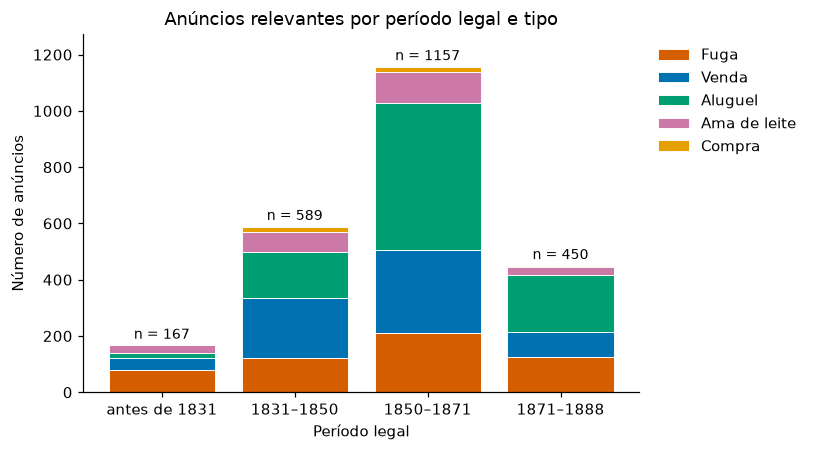

In [4]:
graf = pd.crosstab(df["periodo"], df["tipo"])
graf.columns = [ROTULO_TIPO[c] for c in graf.columns]
cores1 = {ROTULO_TIPO[k]: COR[k] for k in TIPOS}
barras_empilhadas(graf, cores1, "Anúncios relevantes por período legal e tipo", "Período legal", "Número de anúncios",
                  n_topo=graf.sum(axis=1).astype(int).tolist())

**O que mostra:** são 2.560 anúncios relevantes, dos quais 2.363 têm tipo definido (os outros 197 são `aluguel_incerto`, sem marca de pessoa escravizada). O período com mais anúncios é 1850–1871 (1.157), seguido de 1831–1850 (589), 1871–1888 (450) e antes de 1831 (167). O tipo mais comum é aluguel (902), depois venda (638) e fuga (540); ama de leite tem 240 e compra só 43. Compra é pouco numerosa para qualquer comparação, e o período 1871–1888 tem menos de 40% dos anúncios de 1850–1871.

## 2. Sexo da pessoa anunciada
A coluna `c_sexo` tem `f`, `m`, `ambos` (o anúncio fala de mais de uma pessoa) ou vazio (**não diz**).
Abaixo, a **proporção** em cada grupo.

> **Aviso:** essa proporção vem das **frases de busca**, não da população. Buscamos, por exemplo, "preta com leite"
> (que só pode ser mulher) e "escravo fugido". Os grupos de ama de leite e de aluguel são
> dominados por mulheres *por causa do que procuramos*, não porque a população era assim.

In [5]:
df["sexo"] = df["c_sexo"].fillna("não diz")
SEXOS = ["f", "m", "ambos", "não diz"]
ROT_SEXO = {"f": "Feminino", "m": "Masculino", "ambos": "Ambos", "não diz": "Não diz"}
cores_sexo = {ROT_SEXO[k]: COR[k] for k in SEXOS}

def prop_sexo(coluna):
    t = pd.crosstab(df[coluna], df["sexo"]).reindex(columns=SEXOS, fill_value=0)
    n = t.sum(axis=1)
    p = t.div(n, axis=0)
    p.columns = [ROT_SEXO[c] for c in p.columns]
    return p, n

p_per, n_per = prop_sexo("periodo")
p_tipo, n_tipo = prop_sexo("tipo")
print("Sexo por período (%):"); print((p_per * 100).round(1).assign(n=n_per))
print("\nSexo por tipo (%):"); print((p_tipo * 100).round(1).assign(n=n_tipo))

Sexo por período (%):
               Feminino  Masculino  Ambos  Não diz     n
periodo                                                 
antes de 1831      43.5       35.1    8.3     13.1   168
1831–1850          42.9       41.6   13.2      2.3   606
1850–1871          51.9       37.4    6.4      4.3  1247
1871–1888          53.8       35.6    2.0      8.5   539

Sexo por tipo (%):
              Feminino  Masculino  Ambos  Não diz    n
tipo                                                  
fuga              13.3       58.7    3.5     24.4  540
venda             42.0       44.7   13.2      0.2  638
aluguel           59.4       35.0    5.4      0.1  902
ama_de_leite      87.1        2.1   10.0      0.8  240
compra            34.9       46.5   18.6      0.0   43


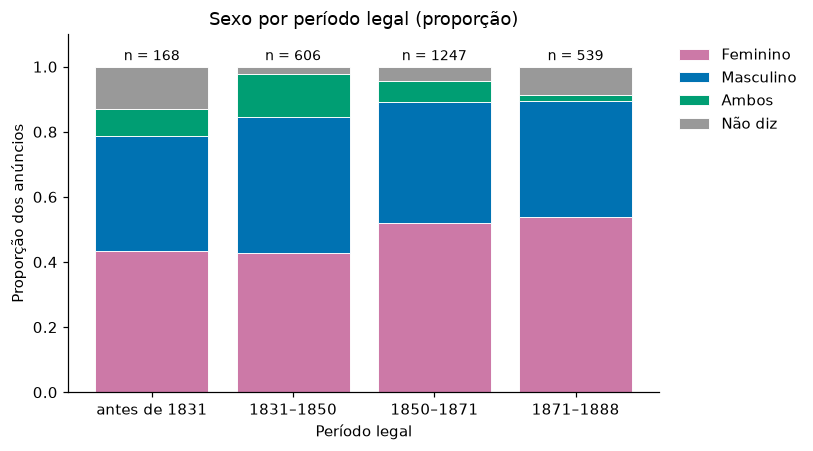

In [6]:
barras_empilhadas(p_per, cores_sexo, "Sexo por período legal (proporção)", "Período legal", "Proporção dos anúncios",
                  proporcao=True, n_topo=n_per.astype(int).tolist())

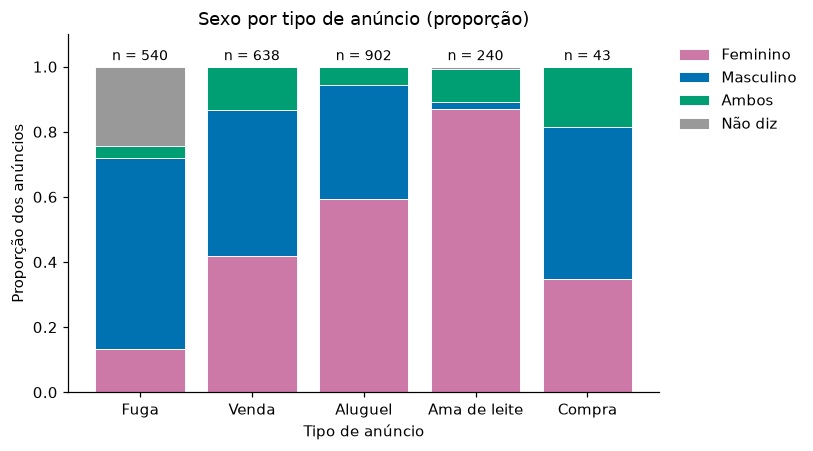

In [7]:
p_tipo.index = [ROTULO_TIPO[i] for i in p_tipo.index]
barras_empilhadas(p_tipo, cores_sexo, "Sexo por tipo de anúncio (proporção)", "Tipo de anúncio", "Proporção dos anúncios",
                  proporcao=True, n_topo=n_tipo.astype(int).tolist())

**O que mostra:** nos anúncios de **ama de leite**, 87,1% são femininos, e em **aluguel** 59,4%; já em **fuga** só 13,3% são femininos, mas 24,4% **não dizem o sexo** (o anúncio descreve a pessoa sem usar uma palavra que o indique). Por período, o feminino sobe de 42,9% (1831–1850) para 53,8% (1871–1888), porém isso acompanha a mudança do **tipo** dominante (aluguel passa de 163 para 520 anúncios entre 1831–1850 e 1850–1871) e **não** deve ser lido como mudança na população.

## 3. Idade
Nem todo anúncio diz a idade. Primeiro, quantos dizem. Depois, as faixas: **até 12**, **13–20**, **21–35** e **36 ou mais**.
Quando o anúncio dá um intervalo ("de 20 a 25 anos"), usamos o ponto médio.

In [8]:
df["idade"] = df[["c_idade_min", "c_idade_max"]].astype(float).mean(axis=1)
tem = df["idade"].notna()
resumo = pd.DataFrame({"anúncios": df.groupby("periodo", observed=True).size(),
                       "com idade": df[tem].groupby("periodo", observed=True).size()}).fillna(0).astype(int)
resumo["% com idade"] = (resumo["com idade"] / resumo["anúncios"] * 100).round(1)
resumo.loc["Total"] = [len(df), int(tem.sum()), round(tem.mean() * 100, 1)]
resumo

,anúncios,com idade,% com idade
periodo,,,
antes de 1831,168,34,20.2
1831–1850,606,167,27.6
1850–1871,1247,166,13.3
1871–1888,539,58,10.8
Total,2560,425,16.6


faixa          até 12  13–20  21–35  36+
periodo                                 
antes de 1831       4     20      9    1
1831–1850          17    101     33   16
1850–1871          23     73     49   21
1871–1888           7     26     19    6


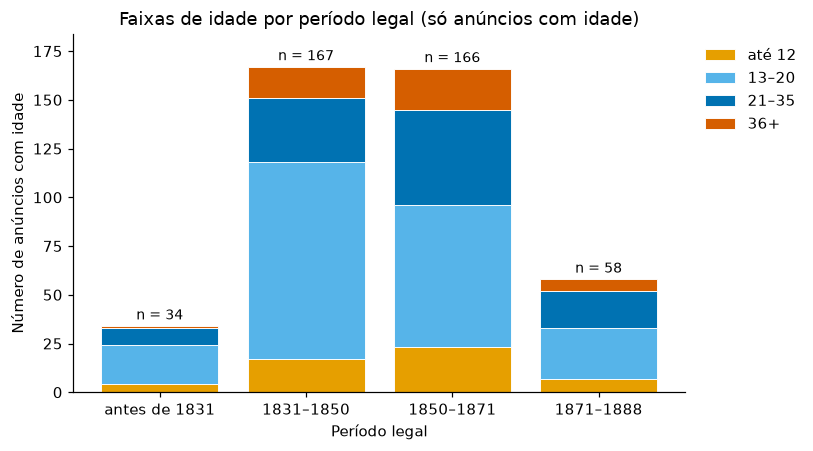

In [9]:
FAIXAS = ["até 12", "13–20", "21–35", "36+"]
df["faixa"] = pd.cut(df["idade"], bins=[-1, 12, 20, 35, 200], labels=FAIXAS)
t3 = pd.crosstab(df["periodo"], df["faixa"]).reindex(columns=FAIXAS, fill_value=0)
print(t3)
cores3 = dict(zip(FAIXAS, ["#E69F00", "#56B4E9", "#0072B2", "#D55E00"]))
barras_empilhadas(t3, cores3, "Faixas de idade por período legal (só anúncios com idade)", "Período legal",
                  "Número de anúncios com idade", n_topo=t3.sum(axis=1).astype(int).tolist())

**O que mostra:** só **379 dos 2.560** anúncios (14,8%) trazem idade; a taxa varia de 25,9% em 1831–1850 a 8,7% em 1871–1888. Entre os 379, a faixa de **13–20 anos** é a maior em todos os períodos (197 de 379, somando os quatro). Antes de 1831 há só 24 casos e em 1871–1888 só 47, então as diferenças entre períodos são frágeis.

## 4. Nações africanas mais citadas
A coluna `c_nacoes` é uma **lista** (um anúncio pode citar mais de uma). "Nação" aqui é o termo usado no anúncio
(Benguela, Mina, Congo…), que dizia de onde vinha ou a que grupo era associada a pessoa; não é uma identidade que ela
mesma escolheu. Contamos quantos anúncios citam cada nação e mostramos as 8 mais citadas em cada período.

Anúncios que citam alguma nação, por período:
{'antes de 1831': 60, '1831–1850': 74, '1850–1871': 51, '1871–1888': 1}

Nações no total: 45


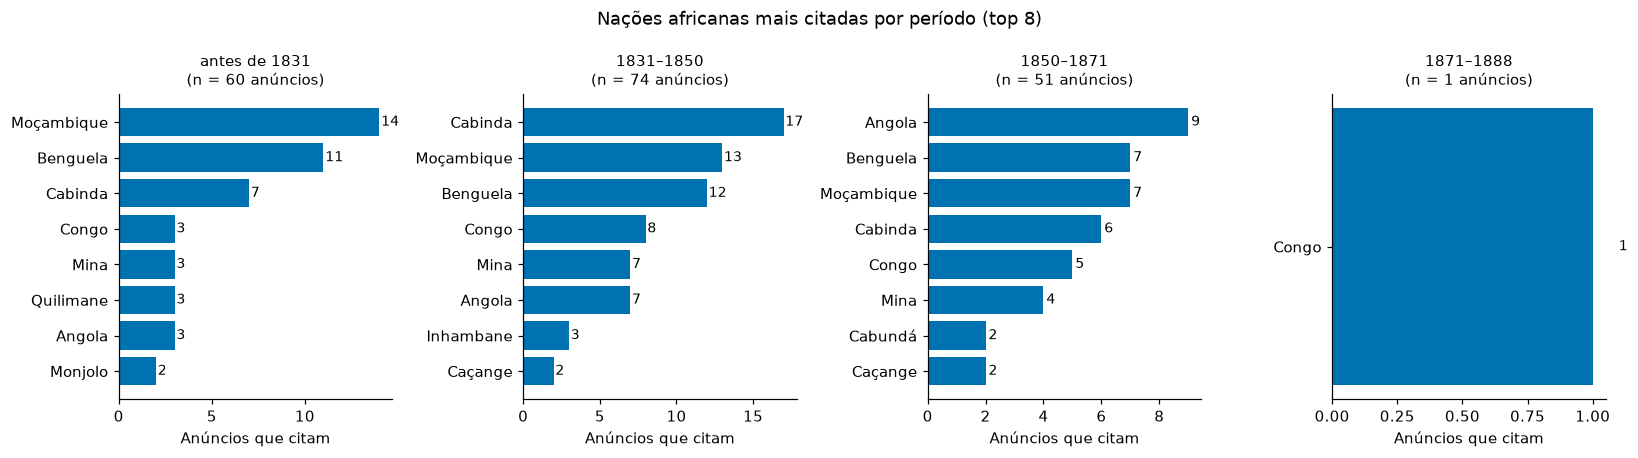

antes de 1831 {'Moçambique': 14, 'Benguela': 11, 'Cabinda': 7, 'Congo': 3, 'Mina': 3, 'Quilimane': 3, 'Angola': 3, 'Monjolo': 2}
1831–1850 {'Cabinda': 17, 'Moçambique': 13, 'Benguela': 12, 'Congo': 8, 'Mina': 7, 'Angola': 7, 'Inhambane': 3, 'Caçange': 2}
1850–1871 {'Angola': 9, 'Benguela': 7, 'Moçambique': 7, 'Cabinda': 6, 'Congo': 5, 'Mina': 4, 'Cabundá': 2, 'Caçange': 2}
1871–1888 {'Congo': 1}


In [10]:
nac = df[["periodo", "c_nacoes"]].explode("c_nacoes").dropna(subset=["c_nacoes"])
com_nacao = df[df["c_nacoes"].map(len) > 0].groupby("periodo", observed=True).size()
print("Anúncios que citam alguma nação, por período:"); print(com_nacao.reindex(PERIODOS, fill_value=0).to_dict())
top = nac["c_nacoes"].value_counts()
print("\nNações no total:", len(top))
fig, eixos = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, per in zip(eixos, PERIODOS):
    c = nac[nac["periodo"] == per]["c_nacoes"].value_counts().head(8)
    if len(c) == 0:
        ax.text(0.5, 0.5, "nenhuma nação\ncitada", ha="center", va="center", transform=ax.transAxes); ax.set_axis_off()
    else:
        ax.barh(c.index[::-1], c.values[::-1], color="#0072B2")
        for y, v in enumerate(c.values[::-1]):
            ax.text(v + 0.1, y, str(v), va="center", fontsize=9)
    ax.set_title(f"{per}\n(n = {int(com_nacao.get(per, 0))} anúncios)", fontsize=10)
    ax.set_xlabel("Anúncios que citam")
fig.suptitle("Nações africanas mais citadas por período (top 8)")
fig.tight_layout(); plt.show()
for per in PERIODOS:
    print(per, nac[nac["periodo"] == per]["c_nacoes"].value_counts().head(8).to_dict())

**O que mostra:** a citação de nação **quase desaparece no último período**: 48 anúncios antes de 1831, 67 em 1831–1850, 44 em 1850–1871 e apenas 3 em 1871–1888 (no total aparecem 16 nações). Antes de 1831 lideram Moçambique (14), Benguela (11), Cabinda (7) e Mina (7); em 1831–1850, Cabinda (17), Mina (15), Moçambique (13) e Benguela (12); em 1850–1871, Angola (9) e depois Mina, Benguela e Moçambique (7 cada). Com tão poucos casos, a ordem das nações no ranking pode mudar com poucos anúncios a mais. **Veredito do quadro de afirmações: sustentada**, mesmo só com o Jornal do Commercio.

## 5. Condição da pessoa
`c_condicao` diz se o anúncio trata a pessoa como **escravizada**, **forra**, **livre** ou se **não dá para saber** (desconhecida).
Em branco, o programa não achou nenhuma palavra de condição ("sem informação").

Contagens:
condicao      escravizado  forro  livre  desconhecida  sem informação  total
tipo                                                                        
fuga                  204     24      7             0             305    540
venda                 105      5      1           527               0    638
aluguel               101     17      5           779               0    902
ama_de_leite           20      5      1           214               0    240
compra                 20      0      0            23               0     43

Proporção (%):
condicao      escravizado  forro  livre  desconhecida  sem informação
tipo                                                                 
fuga                 37.8    4.4    1.3           0.0            56.5
venda                16.5    0.8    0.2          82.6             0.0
aluguel              11.2    1.9    0.6          86.4             0.0
ama_de_leite          8.3    2.1    0.4          89.2             0.0
compra        

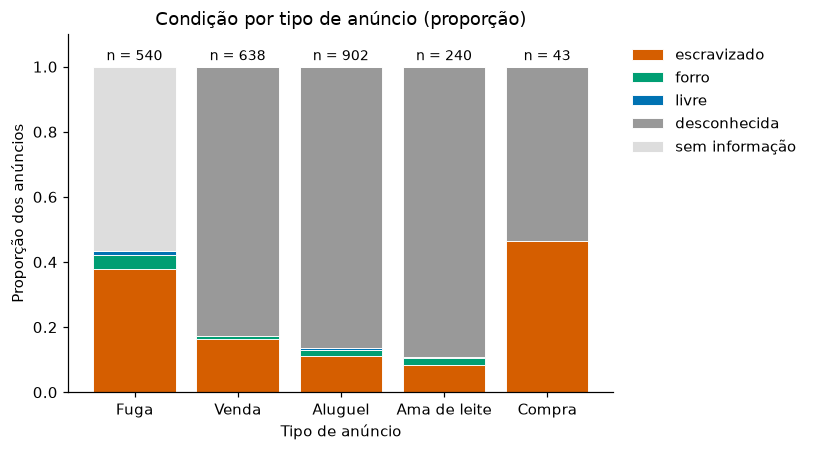

In [11]:
df["condicao"] = df["c_condicao"].fillna("sem informação")
CONDS = ["escravizado", "forro", "livre", "desconhecida", "sem informação"]
t5 = pd.crosstab(df["tipo"], df["condicao"]).reindex(columns=CONDS, fill_value=0)
n5 = t5.sum(axis=1)
p5 = t5.div(n5, axis=0)
print("Contagens:"); print(t5.assign(total=n5))
print("\nProporção (%):"); print((p5 * 100).round(1))
p5.index = [ROTULO_TIPO[i] for i in p5.index]
barras_empilhadas(p5, {k: COR[k] for k in CONDS}, "Condição por tipo de anúncio (proporção)", "Tipo de anúncio",
                  "Proporção dos anúncios", proporcao=True, n_topo=n5.astype(int).tolist())

**O que mostra:** em **aluguel**, 86,4% (779 de 902) estão como "desconhecida" e só 11,2% como escravizado; em **venda** e **ama de leite** o padrão é parecido (82,6% e 89,2%). Isso quer dizer que **o texto não afirma a condição** (o anúncio fala em "uma preta", por exemplo), e não que as pessoas fossem livres. Em **fuga**, 56,5% (305 de 540) ficam "sem informação" e 37,8% saem como escravizados.

## 6. Recompensa nas fugas
Anúncios de fuga costumam oferecer **gratificação** a quem capturasse a pessoa. `c_recompensa` marca se o anúncio a menciona
e `c_valor` guarda o valor, **como aparece no texto** (e lido por OCR, então pode ter erro).

In [12]:
fu = df[df["c_tipo"] == "fuga"]
t6 = fu.groupby("periodo", observed=True).agg(fugas=("id", "size"), com_recompensa=("c_recompensa", "sum"))
t6["com_recompensa"] = t6["com_recompensa"].astype(int)
t6["% com recompensa"] = (t6["com_recompensa"] / t6["fugas"] * 100).round(1)
t6.loc["Total"] = [len(fu), int(fu["c_recompensa"].sum()), round(fu["c_recompensa"].mean() * 100, 1)]
print(t6)
print("\nRecompensa em anúncios que NÃO são fuga:", int(df[df["c_tipo"] != "fuga"]["c_recompensa"].sum()))
print("Fugas com valor lido:", int(fu["c_valor"].notna().sum()))
fu[fu["c_valor"].notna()][["id", "ano", "c_valor"]]

               fugas  com_recompensa  % com recompensa
periodo                                               
antes de 1831     80              49              61.3
1831–1850        123              80              65.0
1850–1871        212              84              39.6
1871–1888        125              25              20.0
Total            540             238              44.1

Recompensa em anúncios que NÃO são fuga: 12
Fugas com valor lido: 8


,id,ano,c_valor
3,5891,1821,1S
9,5898,1821,32:000
202,6988,1850,6s
766,18698,1882,0s
928,23312,1853,4$
1347,29088,1845,2s
1520,30065,1856,5:000
2327,37695,1829,2:000


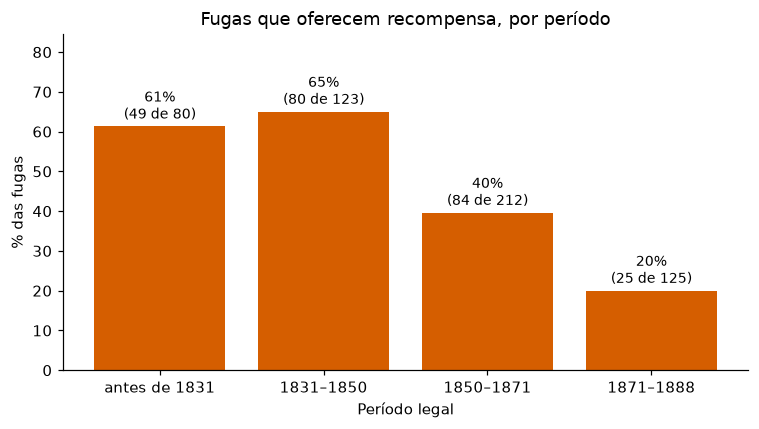

In [13]:
g = t6.drop("Total")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(len(g)), g["% com recompensa"], color="#D55E00")
for i, (pct, n, k) in enumerate(zip(g["% com recompensa"], g["fugas"], g["com_recompensa"])):
    ax.text(i, pct + 0.8, f"{pct:.0f}%\n({k} de {n})", ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index)
ax.set_ylim(0, max(g["% com recompensa"].max() * 1.3, 10))
ax.set_title("Fugas que oferecem recompensa, por período"); ax.set_xlabel("Período legal"); ax.set_ylabel("% das fugas")
fig.tight_layout(); plt.show()

**O que mostra:** 238 das 540 fugas (44,1%) oferecem recompensa, e a proporção **cai com o tempo**: 61,3% antes de 1831, 65,0% em 1831–1850, 39,6% em 1850–1871 e 20,0% em 1871–1888. O valor aparece em apenas 8 fugas (por exemplo 1S, 32:000 e 6s), então **não dá para analisar valores**: são poucos, em moedas e formatos diferentes, e lidos por OCR. **Veredito do quadro de afirmações (caderno `afirmacoes`): sustentada**, e a queda começa depois de 1850 (65,0%, 39,6% e 20,0%). **Atenção (caderno `validacao_campos`):** o código perde recompensas escritas com OCR estragado, sobretudo nos anúncios recentes, então **o nível acima é menor que o real**; conferida à mão (35 fugas por período), a recompensa vai de 80% para 40% (p = 0,001), de modo que a **queda é real** e o número do código vale como tendência.

## 7. Densidade: anúncios relevantes por página
Cada acervo (jornal e década) tem páginas de qualidade e tamanho diferentes, e nós só lemos páginas que a busca apontou.
Dividimos o número de anúncios relevantes pelo número de páginas lidas (`status = ok`) para ver o efeito de cada acervo.

In [14]:
pg = ler_tudo(lambda: db.table("paginas").select("id,bib,ano").eq("status", "ok").order("id"))
paginas_bib = pg.groupby("bib").size().rename("páginas lidas")
rel_bib = df.groupby("bib").size().rename("anúncios relevantes")
nome_bib = df.drop_duplicates("bib").set_index("bib")["acervo"].rename("acervo")
t7 = pd.concat([paginas_bib, rel_bib], axis=1).join(nome_bib).fillna({"anúncios relevantes": 0})
t7["anúncios relevantes"] = t7["anúncios relevantes"].astype(int)
t7["por página"] = (t7["anúncios relevantes"] / t7["páginas lidas"]).round(2)
t7 = t7.sort_values("acervo")
t7.loc["Total"] = [t7["páginas lidas"].sum(), t7["anúncios relevantes"].sum(), "",
                   round(t7["anúncios relevantes"].sum() / t7["páginas lidas"].sum(), 2)]
t7

,páginas lidas,anúncios relevantes,acervo,por página
bib,,,,
094170_01,35,107,Diário do Rio de Janeiro (RJ) - 1821 a 1858,3.06
364568_01,15,47,Jornal do Commercio (RJ) - 1827 a 1829,3.13
364568_02,18,169,Jornal do Commercio (RJ) - 1830 a 1839,9.39
364568_03,30,451,Jornal do Commercio (RJ) - 1840 a 1849,15.03
364568_04,49,842,Jornal do Commercio (RJ) - 1850 a 1859,17.18
364568_05,51,340,Jornal do Commercio (RJ) - 1860 a 1869,6.67
364568_06,44,429,Jornal do Commercio (RJ) - 1870 a 1879,9.75
364568_07,52,175,Jornal do Commercio (RJ) - 1880 a 1889,3.37
706744,5,0,NaN,0.00


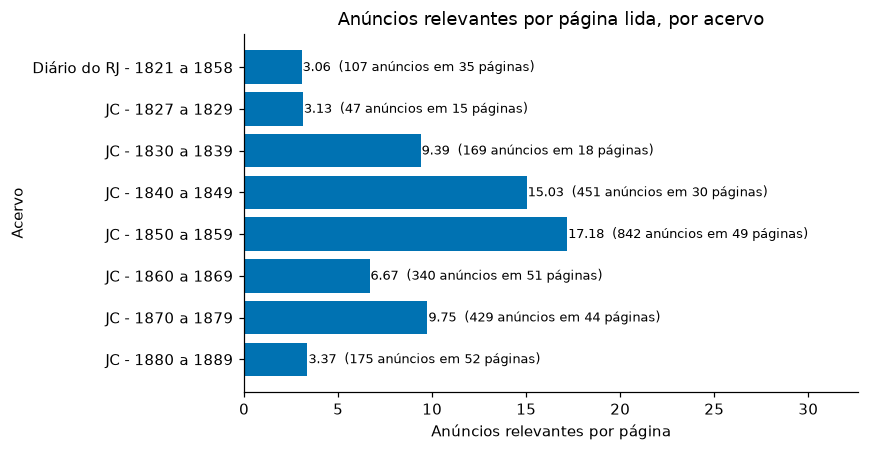

In [15]:
g = t7.drop("Total").dropna(subset=["acervo"])
g = g[g["páginas lidas"] > 0]
rot = g["acervo"].str.replace(" (RJ)", "", regex=False).str.replace("Jornal do Commercio", "JC").str.replace("Diário do Rio de Janeiro", "Diário do RJ").str.replace("Imperio do Brasil: Diario Fluminense", "Diário Fluminense")
fig, ax = plt.subplots(figsize=(8, 4.2))
y = range(len(g))
ax.barh(list(y), g["por página"].astype(float), color="#0072B2")
for i, (v, n, p) in enumerate(zip(g["por página"].astype(float), g["anúncios relevantes"], g["páginas lidas"])):
    ax.text(v + 0.05, i, f"{v:.2f}  ({n} anúncios em {p} páginas)", va="center", fontsize=8.5)
ax.set_yticks(list(y)); ax.set_yticklabels(rot); ax.invert_yaxis()
ax.set_xlim(0, g["por página"].astype(float).max() * 1.9)
ax.set_title("Anúncios relevantes por página lida, por acervo"); ax.set_xlabel("Anúncios relevantes por página"); ax.set_ylabel("Acervo")
fig.tight_layout(); plt.show()

**O que mostra:** a densidade varia muito entre acervos: o Jornal do Commercio de 1850–1859 tem 17,18 anúncios relevantes por página lida e o de 1840–1849 tem 15,03, enquanto o de 1870–1879 tem 9,75, o de 1830–1839 tem 9,39, o de 1860–1869 tem 6,67, o de 1880–1889 tem 3,37, o JC de 1827–1829 3,13 e o Diário do RJ 3,06 (média geral: 8,56). Parte da diferença vem de **como escolhemos as páginas** (a busca e o complemento) e, nos dois acervos mais antigos do JC, de **como os anúncios foram separados** (só pelo texto, sem a imagem: menos preciso). O *Diário Fluminense* (5 páginas) ficou com zero: os 5 "anúncios" que a regra antiga via ali eram relatos de navegação e textos de opinião, e a limpeza os tirou. Contar anúncios por década sem esse cuidado engana.

## 8. O que não podemos concluir

In [16]:
# Números de apoio para a lista abaixo
d80 = df[df["periodo"] == "1871–1888"]
print("1871–1888: anos presentes e anúncios por ano:", d80["ano"].value_counts().sort_index().to_dict())
print("Antes de 1831 por acervo:", df[df["periodo"] == "antes de 1831"]["acervo"].value_counts().to_dict())
alu = d80[d80["c_tipo"] == "aluguel"]
print("Aluguéis 1871–1888:", len(alu), "| condição:", alu["condicao"].value_counts().to_dict())
print("Anúncios por década de acervo (1870 a 1879 vs 1880 a 1889):", df["acervo"].value_counts().to_dict())

1871–1888: anos presentes e anúncios por ano: {1871: 30, 1872: 7, 1873: 15, 1874: 62, 1875: 41, 1876: 38, 1877: 76, 1878: 30, 1879: 65, 1880: 39, 1881: 21, 1882: 40, 1883: 7, 1884: 4, 1885: 19, 1886: 12, 1887: 33}
Antes de 1831 por acervo: {'Diário do Rio de Janeiro (RJ) - 1821 a 1858': 98, 'Jornal do Commercio (RJ) - 1827 a 1829': 47, 'Jornal do Commercio (RJ) - 1830 a 1839': 23}
Aluguéis 1871–1888: 201 | condição: {'desconhecida': 168, 'escravizado': 32, 'forro': 1}
Anúncios por década de acervo (1870 a 1879 vs 1880 a 1889): {'Jornal do Commercio (RJ) - 1850 a 1859': 842, 'Jornal do Commercio (RJ) - 1840 a 1849': 451, 'Jornal do Commercio (RJ) - 1870 a 1879': 429, 'Jornal do Commercio (RJ) - 1860 a 1869': 340, 'Jornal do Commercio (RJ) - 1880 a 1889': 175, 'Jornal do Commercio (RJ) - 1830 a 1839': 169, 'Diário do Rio de Janeiro (RJ) - 1821 a 1858': 107, 'Jornal do Commercio (RJ) - 1827 a 1829': 47}


Pontos de atenção, com os números que a saída acima mostra:

- **A amostra vem de frases de busca, não de sorteio.** Proporções de sexo, tipo ou condição descrevem o que a busca encontrou, não a sociedade da época.
- **1887 entrou, mas 1888 continua sem nenhuma página.** Dos 450 anúncios de 1871–1888, 175 vêm do Jornal do Commercio dos anos 1880 (1880: 39, 1881: 21, 1882: 40, 1883: 7, 1884: 4, 1885: 19, 1886: 12, 1887: 33). As seis frases de fuga que listamos no acervo têm como última página o ano de 1887; **não sabemos se 1888 está fora do acervo digitalizado ou se essas frases não ocorrem nele**. Assim, **a Lei Áurea (13/05/1888) ainda não pode ser descrita**, e a Lei dos Sexagenários (1885) tem poucos casos. Há ainda anos fracos (1883 tem 7; 1884 tem 4; 1872 tem 7). Os 33 anúncios de 1887 vêm de **14 páginas e só de frases de fuga** (o resto do período tem aluguel e venda): o último período fica **mais voltado à fuga** que o conjunto.
- **Antes de 1831 vem de três acervos**: o Diário do Rio (98 anúncios), o JC de 1827–1829 (47) e o JC de 1830–1839 (23). Os dois do JC foram separados **só pelo texto do OCR**, que é menos preciso (anúncios às vezes colados), então o que se vê nesse período tem mais ruído que nos demais.
- **Aluguel é incerto em parte dos casos.** Os 197 anúncios `aluguel_incerto` (sem marca de pessoa escravizada) ficam fora dos tipos e do modelo de tópicos (o caderno de tópicos mostra o que muda se eles entrarem). Dos 201 aluguéis de 1871–1888, 168 estão como "desconhecida" quanto à condição.
- **OCR ruim em parte dos jornais:** palavras erradas fazem o programa deixar de ver sexo, idade, nação ou condição. Os números de preenchimento (por exemplo, 8,7% com idade em 1871–1888) são, na verdade, um **mínimo**.
- **Poucos casos em vários recortes** (compra tem 43 anúncios; nação aparece em 162; idade em 379). Diferenças pequenas entre barras não são evidência.
- **Pendência:** 16 páginas do JC de 1860–1869 (acervo 364568_05, de várias colunas) ainda não tiveram os anúncios separados: a separação só pelo texto não serve para esse tipo de página, e as imagens estão em outra máquina.
- **Limpeza automática:** a classificação `c5` tira dos tipos animais, remédios, relatos de navio, documentos oficiais e papéis que antes entravam como fuga. Isso foi conferido por amostra, mas os rótulos foram atribuídos por Claude, não pelo grupo, e ainda restam alguns casos de lixo.